# Attention-based Neurosymbolic Differentiable Rule Extractor (ANDRE)

**Creator**: Iman Sharifi

## Predicate Selection Heuristic

In [22]:
import numpy as np
import torch
import torch.nn.functional as F

def interpret_neuron_weights_entropy_(body_preds, pred_values, Weights, data_type='boolean', entropy_threshold=1.5):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        body_preds (list): A list of predicate strings for each neuron, like ['b1', 'b2', ...] or ['b1(X1, X2)', 'b2(X3)', ...]
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    
    interpretations = []
    if data_type == 'fuzzy':
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            # Find predicate value of a given neuron
            pred_value = pred_values[i]
            body_pred = body_preds[i]

            # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
            new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

            max_index = np.argmax(new_weights)
            if max_index == 0:
                interpretations.append(f'{body_pred}')
                continue
            elif max_index == 1:
                interpretations.append(f'not({body_pred})')
                continue
            else:
                interpretations.append('1')
    else:
        # For boolean data type, we assume pred_values are binary (0 or 1)
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            max_index = np.argmax(weights)

            if max_index == 0:
                interpretations.append(f'{body_preds[i]}')
            elif max_index == 1:
                interpretations.append(f'not({body_preds[i]})')
            else:
                interpretations.append('1')

    return interpretations

def interpret_neuron_weights_entropy(pred_values, Weights, data_type='boolean', entropy_threshold=0.8):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1',
    only if entropy is below a threshold to ensure confidence in prediction.

    Args:
        pred_values (numpy.ndarray): A 1D array with predicate values (between 0 and 1).
        Weights (list of list): A 2D list where each row is the softmaxed weights of a neuron.
        data_type (str): The type of data, either 'boolean' or 'fuzzy'.
        entropy_threshold (float): The threshold of entropy above which output is considered uncertain.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron, or '?' for uncertain.
    """
    interpretations = []
    if data_type == 'fuzzy':
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            pred_value = pred_values[i]
            new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]
            max_index = np.argmax(new_weights)

            if max_index == 0:
                interpretations.append(f'b{i+1}')
            elif max_index == 1:
                interpretations.append(f'not(b{i+1})')
            else:
                interpretations.append('1')
    else:
        # For boolean data type, we assume pred_values are binary (0 or 1)
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            max_index = np.argmax(weights)

            if max_index == 0:
                interpretations.append(f'b{i+1}')
            elif max_index == 1:
                interpretations.append(f'not(b{i+1})')
            else:
                interpretations.append('1')

    return interpretations

# Network Architecture

In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 20.0  # Example value for beta
LAMBDA = 5.0  # Example value for lambda
GAMMA = 0.5  # Example value for gamma, used in the attention mechanism
# Define CustomNeuron and ANDRE
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

class ANDRE(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(ANDRE, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(LAMBDA*(sum(outputs) - GAMMA))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(LAMBDA*(sum(rule_outputs) - GAMMA))  # Apply sigmoid to the sum

        return activated_output

## Accuracy Metric

In [24]:
def compute_acc_ratio_all_rules_attention(model, x, y, beta=10.0):
    with torch.no_grad():
        rule_outputs = []
        for rule in model.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % model.input_dim]]
                conjunctions.append(neuron(xi).squeeze())
            # Softmin attention over neurons (optional, or just use sum)
            conjunctions = torch.stack(conjunctions, dim=1)  # (batch, num_neurons)
            attention_weights = torch.softmax(-beta * conjunctions, dim=1)
            outputs = (attention_weights * conjunctions).sum(dim=1)  # (batch,)
            activated_outputs = torch.sigmoid(5 * (outputs - 0.5))
            rule_outputs.append(activated_outputs)

        # Stack rule outputs: shape (num_rules, batch)
        rule_outputs_tensor = torch.stack(rule_outputs, dim=0)  # (num_rules, batch)
        # Softmax attention over rules for each sample (dim=0)
        attention_weights = torch.softmax(beta * rule_outputs_tensor, dim=0)
        # Weighted sum over rules for each sample
        final_output = (attention_weights * rule_outputs_tensor).sum(dim=0)  # (batch,)
        # Compute accuracy
        preds = (final_output > 0.5).float()
        acc = (preds == (y > 0.5)).float().mean().item()
        return acc


## Dataset Generation

Desired Rule:

$h \leftarrow h_1 \vee h_2$, where $h_1 \leftarrow b_1 \wedge \neg b_3$, and $h_2 \leftarrow \neg b_2 \wedge b_4$.

In [25]:
# Dataset
torch.manual_seed(42)
num_neurons_per_rule = 4
input_dim = num_neurons_per_rule
num_samples = 200
X_train = (torch.rand(num_samples, input_dim) > 0.5).float()  # Random binary features
y_train = ((((1 - X_train[:, 1]) > 0.5) & (X_train[:, 3] > 0.5))|((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5))).float()


## Main Loop

Num Rules: 1, Restart 1/3, Final Loss: 0.4858.
Overall accuracy ratio: 0.8150
Num Rules: 1, Restart 2/3, Final Loss: 0.4732.
Overall accuracy ratio: 0.8250
Num Rules: 1, Restart 3/3, Final Loss: 0.5636.
Overall accuracy ratio: 0.7400
Num Rules: 2, Restart 1/3, Final Loss: 0.1255.
Overall accuracy ratio: 1.0000
Num Rules: 2, Restart 2/3, Final Loss: 0.1259.
Overall accuracy ratio: 1.0000
Num Rules: 2, Restart 3/3, Final Loss: 0.1248.
Overall accuracy ratio: 1.0000


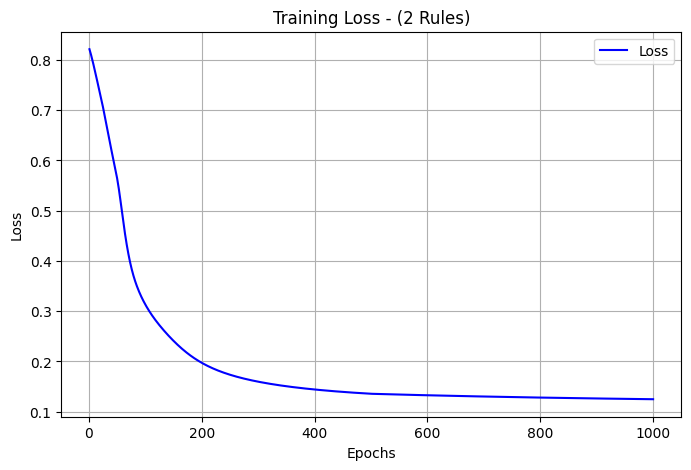


Final Weights of the Network:
Rule 1: [[0.9766137003898621, 0.01310141570866108, 0.010284881107509136], [0.009354276582598686, 0.016287347301840782, 0.9743583798408508], [0.012974421493709087, 0.9777136445045471, 0.009311950765550137], [0.0030313879251480103, 0.001071456354111433, 0.9958971738815308]]
Rule 2: [[0.01656079851090908, 0.008814127184450626, 0.9746251106262207], [0.010559729300439358, 0.9797152280807495, 0.009725082665681839], [0.002026695990934968, 0.003010337008163333, 0.9949629306793213], [0.9792678356170654, 0.00961458683013916, 0.011117572896182537]]

Final SubRules:
Rule 1: h :- b1 and not(b3). -> Accuracy: 1.0 

Rule 2: h :- not(b2) and b4. -> Accuracy: 1.0 


Final Rule:
h :- b1 and not(b3) OR not(b2) and b4.


In [26]:
from collections import Counter
# Parameters
Num_rules = 2
num_epochs = 1000
num_restarts = 3
similarity_weight = 0.1
entropy_weight = 0.01

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_acc_ratio = 0
best_losses = []

for num_rules in range(Num_rules):

    for restart in range(num_restarts):
        andre_model = ANDRE(num_rules + 1, num_neurons_per_rule, input_dim)
        # criterion = nn.BCEWithLogitsLoss()
        criterion = nn.BCELoss()  # Use BCELoss for sigmoid outputs
        optimizer = optim.AdamW(andre_model.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = andre_model(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            # Cosine similarity loss
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = andre_model.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = andre_model.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            # Entropy regularization for exploration
            entropy_term = sum(andre_model.entropies)

            total_loss = bce_loss + entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(andre_model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules + 1}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            best_losses = losses_nsre

        acc_ratio_all = compute_acc_ratio_all_rules_attention(andre_model, X_train, y_train)
        if acc_ratio_all > best_acc_ratio:
            best_acc_ratio = acc_ratio_all
            best_state_dict = deepcopy(andre_model.state_dict())
            best_num_rules = num_rules + 1

        print(f"Overall accuracy ratio: {acc_ratio_all:.4f}")
# Load the best model
best_model = ANDRE(best_num_rules, num_neurons_per_rule, input_dim)
best_model.load_state_dict(best_state_dict)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss - ({best_num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)
print("\nFinal Weights of the Network:")
for i, weights in enumerate(Weights_nsre):
    print(f"Rule {i+1}: {weights}")

# Rule interpretation
Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_entropy(pred_values, weights, data_type='boolean', entropy_threshold=1.5)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    rule_accuracy = float(count/len(Extracted_rules))
    # print(f"The most repeated rule is: '{most_common_rule}'")
    # print(f"Accuracy over training data: {rule_accuracy}.")
    # Save the most common rule with its accuracy
    Final_rules.append((most_common_rule, rule_accuracy))

# Sort rules by accuracy
Final_rules.sort(key=lambda x: x[1], reverse=True)
# Extract the rules from the sorted list
Final_rules_ = [rule[0] for rule in Final_rules]
# Print the final rules with their accuracies
print("\n======================================")
print("Final SubRules:")
for i, rule in enumerate(Final_rules):
    print(f"Rule {i+1}: {rule[0]} -> Accuracy: {rule[1]} \n")

# remove the "h :- " part from each rule
Final_rules = [rule.replace(f"h :- ", "") for rule_num, rule in enumerate(Final_rules_)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")
